[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HernanBustamanteG/lapis26-p3-corrientes/blob/main/notebooks/05_hito5_clasificacion.ipynb)

# 05 · Hito 5: ¿qué corrientes sienten qué?

Preguntas del enunciado: qué corrientes están dominadas por el **reflejo** ($f_{\rm reflex} > 0.6$) y cuáles por el
**torque** o tirón directo ($< 0.4$); mapa de $f_{\rm reflex}$ sobre los polos iniciales; dependencia con la distancia,
la orientación del plano (respecto de la órbita de la LMC y de $\mathbf a_{\rm MW}$), el acercamiento a la LMC, el
sentido de giro, la longitud y la edad de los restos; qué métrica es más sensible a cada efecto; y si hay órbitas
en que los dos efectos se cancelan.

In [11]:
# Celda 1: entorno. En Colab clona el repositorio, instala versiones fijas y monta Google Drive (las salidas
# quedan en MyDrive/lapis26_p3/salidas). Si numpy cambia de version, la sesion se reinicia UNA vez:
# vuelve a ejecutar esta celda. En una maquina propia solo comprueba versiones.
import os, sys, subprocess
REPO_URL = "https://github.com/HernanBustamanteG/lapis26-p3-corrientes.git"
USAR_DRIVE = True
if "google.colab" in sys.modules:
    RAIZ = "/content/lapis26-p3-corrientes"
    if not os.path.isdir(RAIZ):
        subprocess.run(["git", "clone", "-q", REPO_URL, RAIZ], check=True)
else:
    RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, RAIZ)
os.chdir(RAIZ)
from p3streams import entorno
if entorno.en_colab():
    entorno.preparar_colab(RAIZ, montar_drive=USAR_DRIVE)
entorno.resumen();

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Python 3.13.18
  numpy       2.2.6
  scipy       1.16.3
  astropy     7.2.3
  gala        1.12.0
  matplotlib  3.10.0
  pandas      2.2.3
  healpy      1.20.1
  galstreams  1.2.1
Salidas en: /content/drive/MyDrive/lapis26_p3/salidas
ffmpeg: /usr/bin/ffmpeg | CPU: 2
Entorno OK


In [12]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
import matplotlib.pyplot as plt
from p3streams import config as C, util as U, estilo as E
E.usar()
SAL = U.carpeta_nueva("05_hito5")          # carpeta nueva de este notebook (nada se pisa)
FUENTE = "notebooks/05_hito5.ipynb, p3streams " + C.VERSION + ", " + U.ahora()
print("Salidas de este notebook:", SAL)

Salidas de este notebook: /content/drive/MyDrive/lapis26_p3/salidas/05_hito5_20261030_015231


In [13]:
from p3streams import resultados as R, analisis as An, metricas as Me, figuras as F, potenciales as P
PROPIOS = False          # True: usar la corrida propia mas reciente (salidas/) en vez de la incluida en resultados/
DF, ORIGEN = R.cargar("catalogo_principal", propios=PROPIOS)
print("Catalogo: %d corrientes, leido de %s" % (len(DF), ORIGEN))
sis = P.integrar_sistema()          # el mismo sistema MW + LMC (1.8e11 Msun) del catalogo
DF = An.agregar_geometria(DF, sis)

Catalogo: 288 corrientes, leido de /content/lapis26-p3-corrientes/resultados/catalogo_principal.csv


### Sensibilidad de cada métrica

Piso = mediana en el modelo A. Para el cambio del polo, el piso de referencia es la dispersión intrínseca de los
polos en A (cuánto se puede definir un polo medio en la práctica).

In [14]:
SENS = An.tabla_sensibilidad(DF).round(2)
SENS.to_csv(os.path.join(SAL, "hito5_sensibilidad.csv"), index=False)
SENS

,metric,floor_A,median |dM_reflex|,median |dM_direct|,median |dM_full|,frac reflex > floor,frac direct > floor,reflex,mixed,torque
0,change of the mean pole (deg),NaN,4.50,6.25,5.19,0.78,0.95,97,65,126
1,PM misalignment (deg),2.06,3.81,3.78,2.50,0.73,0.77,111,79,98
2,pole tilt from initial pole (deg),4.12,3.87,4.29,3.95,0.47,0.53,116,58,114
3,"plane tilt, SVD (deg)",4.05,2.00,3.26,2.42,0.24,0.40,78,56,154
4,pole spread (deg),1.94,4.26,4.41,1.94,0.82,0.66,115,91,82


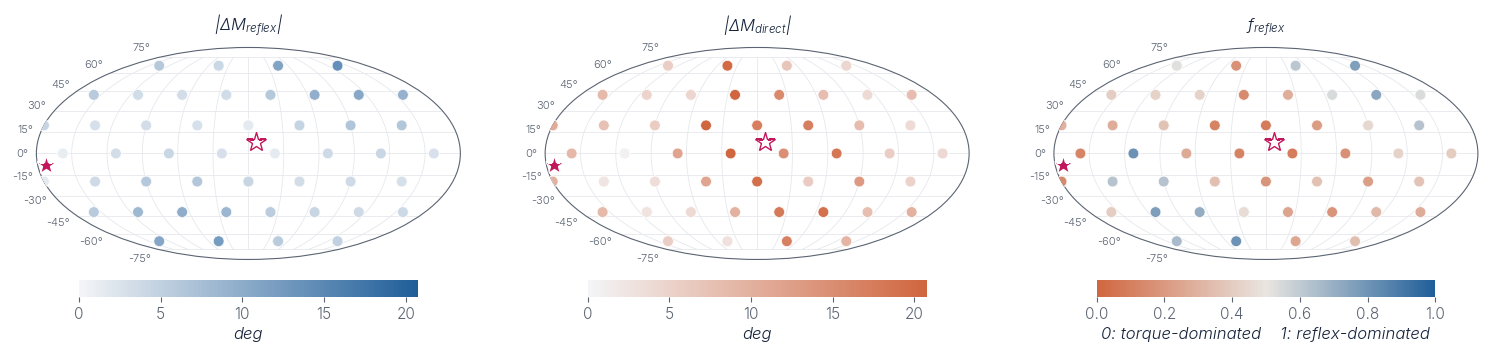

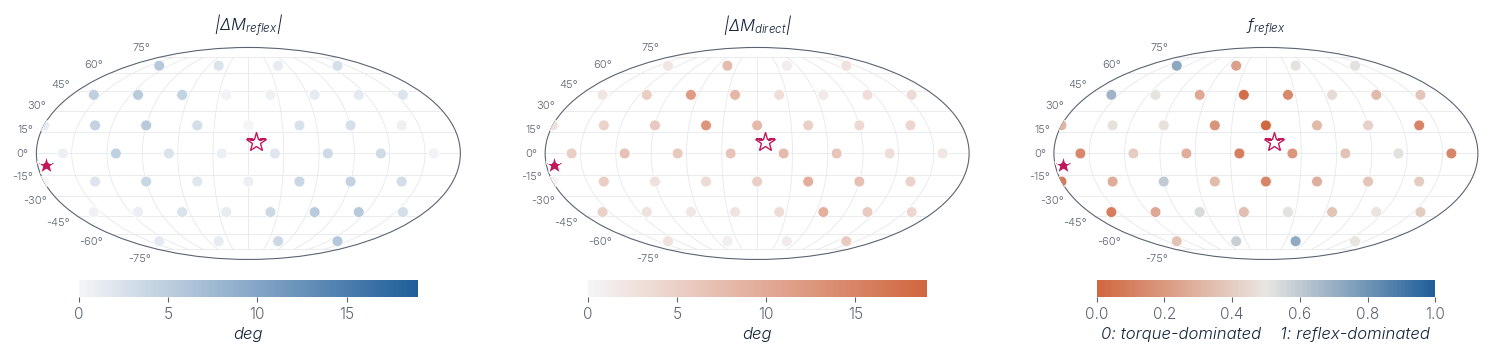

In [15]:
for met in ("dpolo", "desalineamiento_deg"):
    fig = F.mapas_clasificacion(DF, met, sis=sis)
    E.guardar(fig, os.path.join(SAL, "hito5_mapa_%s.png" % met),
              "Milestone 5. Initial orbital poles of the %d streams (Mollweide, Galactocentric frame of the MW; "
              "longitude increases to the left) coloured by the reflex perturbation |B - A|, the direct-pull "
              "perturbation |C - A| and the reflex fraction f_reflex of the %s. Filled star: orbital pole of the "
              "LMC today; open star: the opposite pole. Each pole hosts six streams (3 families x 2 phases): "
              "the colours overlap." % (len(DF), An.METRICAS[met]), FUENTE, pdf=True)
    plt.show()

Cada polo tiene seis corrientes (tres familias y dos fases) que se superponen en el mapa. Por familia:

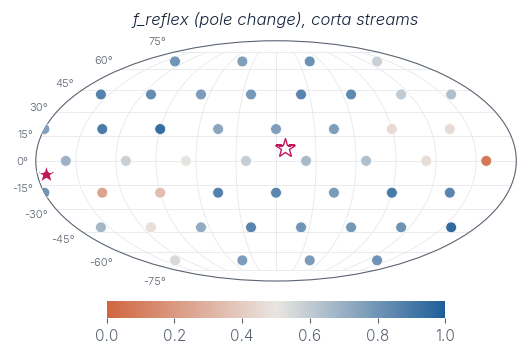

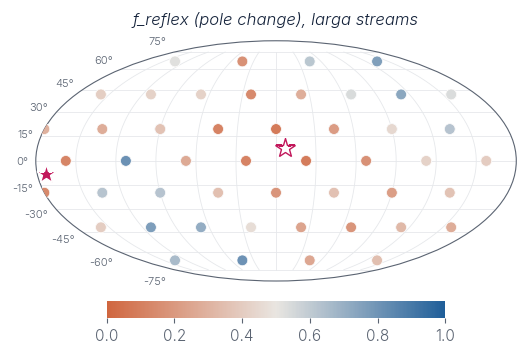

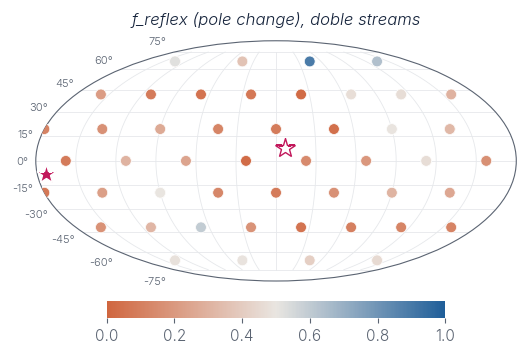

col_0,mixed,reflex,torque
familia,,,
corta,20,66,10
doble,21,3,72
larga,24,28,44


In [16]:
for fam in ("corta", "larga", "doble"):
    d = DF[DF["familia"] == fam]
    fig = F.mapa_polos(d, ["dpolo_f_reflex_todo"], ["f_reflex (pole change), %s streams" % fam], sis=sis,
                       cmaps={"dpolo_f_reflex_todo": F.cmap_f_reflex()}, rangos={"dpolo_f_reflex_todo": (0, 1)})
    E.guardar(fig, os.path.join(SAL, "hito5_mapa_f_%s.png" % fam), "Reflex fraction of the pole change for the "
              "%s family (median of the two phases overlaps: both are plotted)." % fam, FUENTE)
    plt.show()
CL = pd.crosstab(DF["familia"], An.clases(DF, "dpolo"))
CL.to_csv(os.path.join(SAL, "hito5_clases_por_familia.csv"))
CL

### Distancia, acercamiento a la LMC y longitud

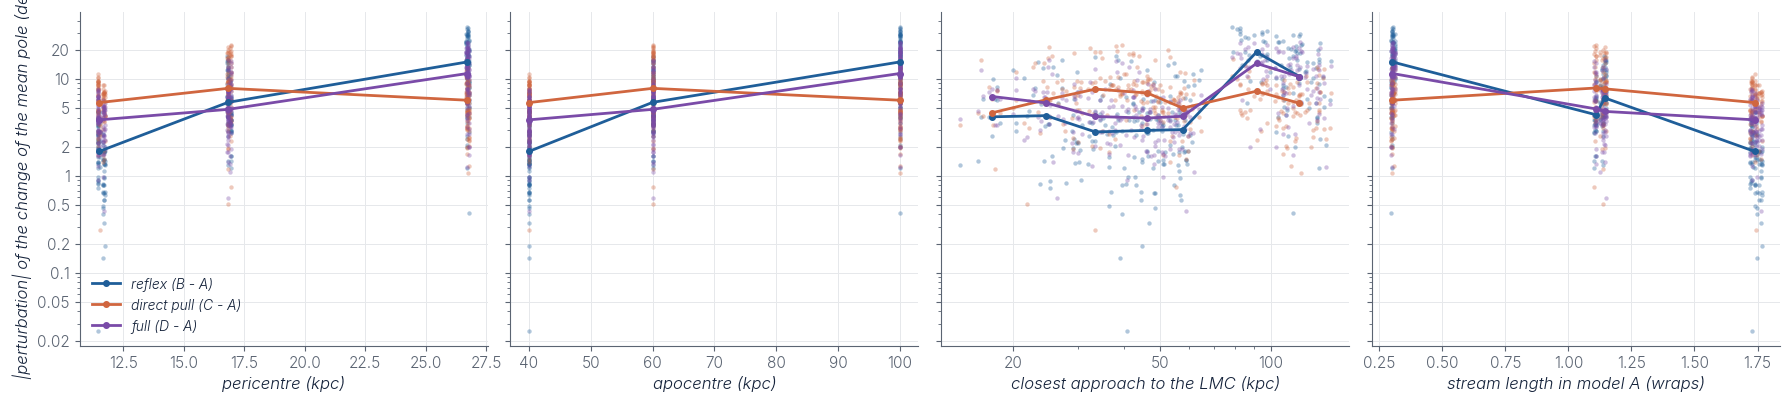

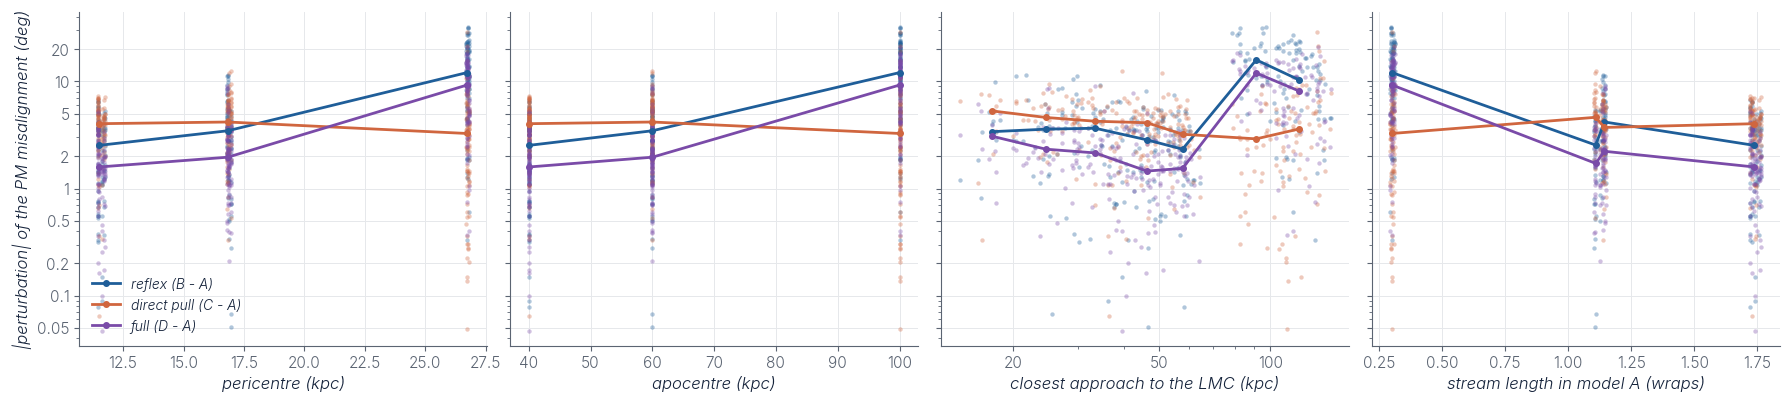

In [17]:
for met in ("dpolo", "desalineamiento_deg"):
    fig = F.tendencias(DF, met, ylabel="|perturbation| of the " + An.METRICAS[met])
    E.guardar(fig, os.path.join(SAL, "hito5_tendencias_%s.png" % met), "Milestone 5. Perturbation of the %s by "
              "the reflex motion alone (B - A), the direct pull alone (C - A) and both (D - A), against "
              "pericentre, apocentre, closest approach to the LMC and stream length. Lines: medians in bins."
              % An.METRICAS[met], FUENTE, pdf=True)
    plt.show()

### Distancia y longitud por separado

En la grilla principal cada familia fija a la vez la distancia y la masa del progenitor (y con ellas la longitud),
así que las tendencias de arriba mezclan los dos factores. Dos catálogos más los separan (12 polos HEALPix cada uno):
*distancia* ($r_{\rm apo}$ = 30, 45, 70, 100, 150 kpc con $10^7\,M_\odot$) y *longitud* ($r_{\rm apo}$ = 60 kpc con
$M_{\rm prog} = 10^6, 10^7, 10^8\,M_\odot$).

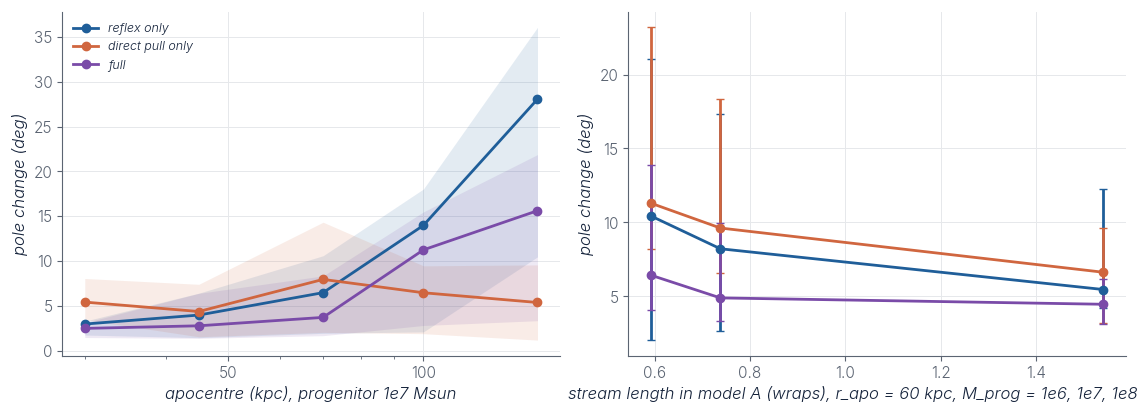

Figura: hito5_distancia_longitud.png 
Milestone 5, distance and length separated. Left: median (and 16-84 per cent range) pole change against apocentre for 1e7 Msun progenitors on 12 HEALPix poles. Right: against stream length in model A, changing only the progenitor mass at a fixed apocentre of 60 kpc.
       peri_kpc  longitud_vueltas_A  dpolo_B_todo  dpolo_C_todo  dpolo_D_todo  \
r_apo                                                                           
30         8.60                1.48          2.97          5.42          2.49   
45        12.85                0.98          3.98          4.37          2.78   
70        19.37                0.71          6.47          7.95          3.72   
100       26.71                0.30         13.98          6.46         11.25   
150       38.27                0.14         28.05          5.38         15.61   

       dpolo_f_reflex_todo  
r_apo                       
30                    0.30  
45                    0.44  
70         

In [18]:
DIS, _ = R.cargar("catalogo_distancia", propios=PROPIOS)
LON, _ = R.cargar("catalogo_longitud", propios=PROPIOS)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3))
for k, m, nom in (("dpolo_B_todo", "B", "reflex only"), ("dpolo_C_todo", "C", "direct pull only"), ("dpolo_D_todo", "D", "full")):
    g = DIS.groupby("r_apo")[k]
    ax[0].fill_between(g.median().index, g.quantile(0.16), g.quantile(0.84), color=E.COLOR_MODELO[m], alpha=0.12, lw=0)
    ax[0].plot(g.median().index, g.median().values, "-o", color=E.COLOR_MODELO[m], lw=2, label=nom)
    g = LON.groupby("m_prog")
    ax[1].errorbar(g["longitud_vueltas_A"].median(), g[k].median(), yerr=[g[k].median() - g[k].quantile(0.16), g[k].quantile(0.84) - g[k].median()],
                   fmt="-o", color=E.COLOR_MODELO[m], lw=2, capsize=3, label=nom)
ax[0].set_xlabel("apocentre (kpc), progenitor 1e7 Msun"); ax[0].set_xscale("log")
ax[1].set_xlabel("stream length in model A (wraps), r_apo = 60 kpc, M_prog = 1e6, 1e7, 1e8 Msun")
for A in ax:
    A.set_ylabel("pole change (deg)"); E.grilla(A)
ax[0].legend(fontsize=9)
fig.tight_layout()
PIE = 'Milestone 5, distance and length separated. Left: median (and 16-84 per cent range) pole change against apocentre for 1e7 Msun progenitors on 12 HEALPix poles. Right: against stream length in model A, changing only the progenitor mass at a fixed apocentre of 60 kpc.'
E.guardar(fig, os.path.join(SAL, 'hito5_distancia_longitud.png'), PIE, FUENTE, pdf=True)
plt.show()
print("Figura:", 'hito5_distancia_longitud.png', "\n" + PIE)
print(DIS.groupby("r_apo")[["peri_kpc", "longitud_vueltas_A", "dpolo_B_todo", "dpolo_C_todo", "dpolo_D_todo", "dpolo_f_reflex_todo"]].median().round(2))
print(LON.groupby("m_prog")[["longitud_vueltas_A", "dpolo_B_todo", "dpolo_C_todo", "dpolo_D_todo", "dpolo_f_reflex_todo"]].median().round(2))

### Estrella a estrella: ¿dónde se cancelan los dos efectos?

Como los cuatro modelos usan la misma semilla, la estrella *i* es la misma en A, B, C y D. Para cada estrella de las
corrientes del catálogo principal: el ángulo entre su polo orbital en B (o C, D) y en A, en función de su radio hoy.

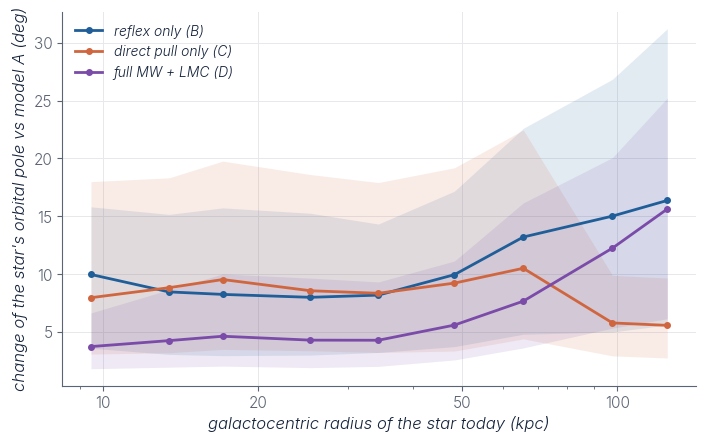

Figura: hito5_por_radio.png 
Milestone 5, star by star. Change of each star's orbital pole relative to the same star in the isolated MW (same seed in the four models), against the star's galactocentric radius today, for all streams of the main catalogue: medians and 16-84 per cent ranges. Reflex only (B), direct pull only (C) and both (D).


,r_min,r_max,r_med,n_estrellas,med_B,p16_B,p84_B,med_C,p16_C,p84_C,med_D,p16_D,p84_D
0,5,10,9.46,7060,9.98,3.62,15.82,7.98,3.11,18.00,3.76,1.84,6.66
1,10,15,13.42,56368,8.48,3.08,15.17,8.84,3.23,18.32,4.27,1.98,8.66
2,15,20,17.08,101272,8.26,2.97,15.73,9.55,3.52,19.77,4.65,2.07,10.03
3,20,30,25.30,194240,8.01,3.02,15.27,8.58,3.40,18.61,4.31,1.94,9.67
4,30,40,34.30,219088,8.20,3.25,14.34,8.36,3.25,17.92,4.30,2.05,9.34
5,40,60,48.23,306264,9.96,3.75,17.17,9.24,3.37,19.19,5.61,2.60,11.14
6,60,80,65.66,128824,13.22,4.82,22.60,10.52,4.42,22.46,7.68,3.64,16.16
7,80,120,97.91,425860,15.02,5.02,26.84,5.80,2.95,9.91,12.26,5.35,20.07
8,120,200,125.20,1600,16.38,5.62,31.20,5.59,2.77,9.67,15.64,6.16,25.21


In [19]:
RAD, _ = R.cargar("por_radio_principal")
fig = F.por_radio(RAD)
PIE = "Milestone 5, star by star. Change of each star's orbital pole relative to the same star in the isolated MW (same seed in the four models), against the star's galactocentric radius today, for all streams of the main catalogue: medians and 16-84 per cent ranges. Reflex only (B), direct pull only (C) and both (D)."
E.guardar(fig, os.path.join(SAL, 'hito5_por_radio.png'), PIE, FUENTE, pdf=True)
plt.show()
print("Figura:", 'hito5_por_radio.png', "\n" + PIE)
RAD.round(2)

### Orientación y sentido de giro

¿Una fuerza uniforme perpendicular al plano de la corriente la inclina más? Se mide con
$|\hat{\mathbf n}_0\cdot\hat{\mathbf a}_{\rm MW}|$, con $\hat{\mathbf a}_{\rm MW}$ la dirección media de la aceleración de la MW
en el último Gyr (pesada por su módulo; apunta hacia la LMC). El sentido de giro: prógrada si el polo inicial
está del mismo lado que el polo orbital de la LMC.

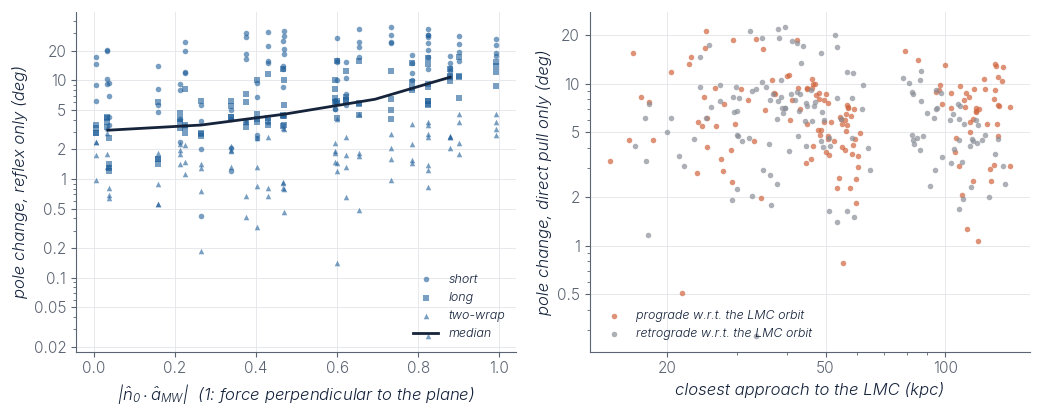

Figura: hito5_orientacion.png 
Milestone 5. Left: pole change caused by the reflex motion alone against |n0 . a_MW|, where a_MW is the |a|-weighted mean direction of the MW acceleration over the last Gyr (1: the uniform force is perpendicular to the stream plane). Right: pole change caused by the direct pull alone against the closest approach to the LMC, for streams rotating in the same sense as the LMC orbit (prograde) or opposite (retrograde).
Spearman (|n0.a_MW|, cambio del polo por reflejo): rho = 0.33, p = 1.4e-08
             dpolo_B_todo  dpolo_C_todo  dpolo_D_todo  dmin_lmc_kpc
sentido_lmc                                                        
prograde             4.09          6.71          5.17         54.21
retrograde           4.70          6.10          5.20         46.91
Tiron directo, prograda vs retrograda: Mann-Whitney p = 3.9e-01


In [20]:
fig = F.orientacion(DF)
PIE = 'Milestone 5. Left: pole change caused by the reflex motion alone against |n0 . a_MW|, where a_MW is the |a|-weighted mean direction of the MW acceleration over the last Gyr (1: the uniform force is perpendicular to the stream plane). Right: pole change caused by the direct pull alone against the closest approach to the LMC, for streams rotating in the same sense as the LMC orbit (prograde) or opposite (retrograde).'
E.guardar(fig, os.path.join(SAL, 'hito5_orientacion.png'), PIE, FUENTE, pdf=True)
plt.show()
print("Figura:", 'hito5_orientacion.png', "\n" + PIE)
from scipy.stats import spearmanr
r = spearmanr(DF["perp_aMW"], DF["dpolo_B_todo"])
print("Spearman (|n0.a_MW|, cambio del polo por reflejo): rho = %.2f, p = %.1e" % (r.statistic, r.pvalue))
print(DF.groupby("sentido_lmc")[["dpolo_B_todo", "dpolo_C_todo", "dpolo_D_todo", "dmin_lmc_kpc"]].median().round(2))
from scipy.stats import mannwhitneyu
a, b = (DF.loc[DF["sentido_lmc"] == s, "dpolo_C_todo"] for s in ("prograde", "retrograde"))
print("Tiron directo, prograda vs retrograda: Mann-Whitney p = %.1e" % mannwhitneyu(a, b).pvalue)

### Restos viejos y jóvenes

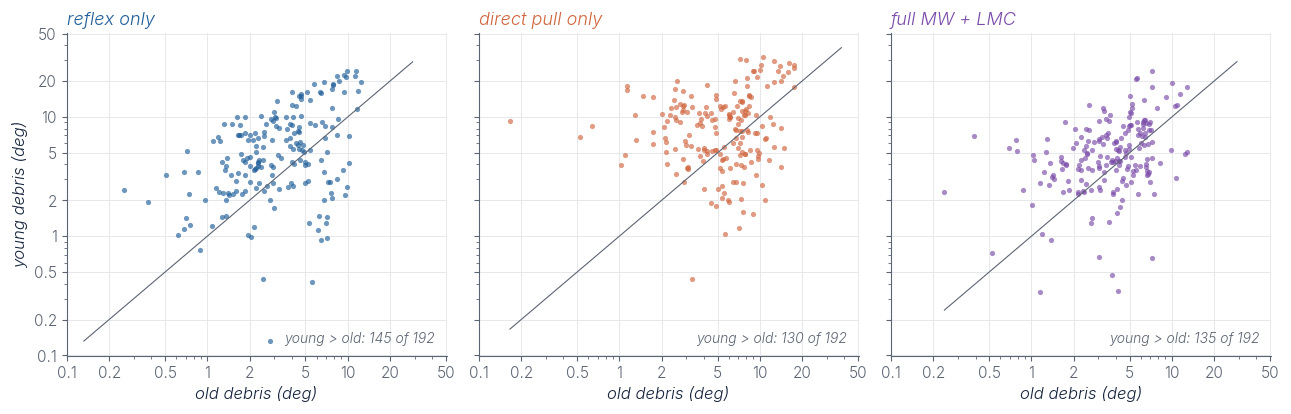

Figura: hito5_viejo_joven.png 
Milestone 5. Pole change of the old debris (released before the median release time) against the young debris, for the long and two-wrap streams, for each effect. Line: one to one.


In [21]:
fig = F.viejo_joven(DF, "dpolo")
PIE = 'Milestone 5. Pole change of the old debris (released before the median release time) against the young debris, for the long and two-wrap streams, for each effect. Line: one to one.'
E.guardar(fig, os.path.join(SAL, 'hito5_viejo_joven.png'), PIE, FUENTE, pdf=True)
plt.show()
print("Figura:", 'hito5_viejo_joven.png', "\n" + PIE)

### No linealidad y cancelaciones

No linealidad: $|\Delta M_{\rm full} - (\Delta M_{\rm reflex} + \Delta M_{\rm direct})| / (|\Delta M_{\rm reflex}| + |\Delta M_{\rm direct}|)$.
Cancelación (cambio vectorial del polo): el efecto total es menor que la mitad del mayor de los dos efectos
separados (y este supera 1°).

In [22]:
filas = []
for met in ("desalineamiento_deg", "tilt_polo_deg", "tilt_plano_deg", "dispersion_polos_deg"):
    nl = An.no_linealidad(DF, met)
    filas.append(dict(metric=An.METRICAS[met], median_nonlinear=np.nanmedian(nl), frac_above_0_5=np.nanmean(nl > 0.5)))
NL = pd.DataFrame(filas).round(2)
canc = An.cancelaciones(DF)
print("Cancelaciones: %d de %d corrientes (%.0f %%)" % (canc.sum(), len(DF), 100 * canc.mean()))
print(DF.loc[canc].groupby("familia").size().rename("n con cancelacion"))
print(DF.loc[canc, ["perp_aMW", "cos_polo_lmc", "dmin_lmc_kpc"]].median().round(2).rename("mediana (cancelan)"))
print(DF.loc[~canc, ["perp_aMW", "cos_polo_lmc", "dmin_lmc_kpc"]].median().round(2).rename("mediana (resto)"))
NL

Cancelaciones: 69 de 288 corrientes (24 %)
familia
corta    10
doble    16
larga    43
Name: n con cancelacion, dtype: int64
perp_aMW         0.65
cos_polo_lmc    -0.11
dmin_lmc_kpc    48.57
Name: mediana (cancelan), dtype: float64
perp_aMW         0.43
cos_polo_lmc     0.07
dmin_lmc_kpc    53.38
Name: mediana (resto), dtype: float64


,metric,median_nonlinear,frac_above_0_5
0,PM misalignment (deg),0.67,0.72
1,pole tilt from initial pole (deg),0.44,0.38
2,"plane tilt, SVD (deg)",0.48,0.46
3,pole spread (deg),0.73,0.84


## Discusión del hito 5

Números de la corrida incluida en `resultados/` (si se rehace con `PROPIOS = True`, mirar las salidas de arriba).
Entre corchetes, el estatus de cada afirmación.

**1. Lo que decide quién domina es la distancia.** Con el cambio vectorial del polo, 66 de las 96 corrientes
cortas ($r_{\rm apo}$ = 100 kpc) están dominadas por el reflejo y 72 de las 96 de dos vueltas (40 kpc) por el
torque; las largas (60 kpc) quedan repartidas [comprobado]. El catálogo *distancia*, con la misma masa, lo aísla:
la mediana de $f_{\rm reflex}$ sube de forma monótona de 0.30 (30 kpc) a 0.80 (150 kpc) [comprobado].
Una explicación [deducido]: la fuerza ficticia $-\mathbf a_{\rm MW}$ es casi la misma en todo el halo, pero una
órbita interna da muchas vueltas mientras la LMC pasa y su torque se promedia (respuesta adiabática), mientras
que una órbita externa, de período largo, no alcanza a promediarlo.

**2. Cerca del centro los dos efectos se cancelan.** Estrella por estrella, el reflejo solo y el tirón solo inclinan
cada uno las órbitas ~8–10° a cualquier radio. Juntos (D) quedan en ~4° dentro de ~40 kpc; más allá de ~80 kpc,
D se acerca a B (12–16°) y el tirón solo baja a ~6° [comprobado]. Es lo que anticipa el enunciado: en el centro
queda solo el campo de marea de la LMC.

**3. Orientación.** El cambio del polo por el reflejo crece con $|\hat{\mathbf n}_0\cdot\hat{\mathbf a}_{\rm MW}|$
(Spearman ρ ≈ 0.33, p ~ 10⁻⁸): sí, una fuerza uniforme perpendicular al plano lo inclina más [comprobado]. El
**sentido de giro** respecto de la LMC no da una diferencia significativa en la grilla principal (p ≈ 0.4), aunque
en el piloto sí parecía haberla: con 72 corrientes era una fluctuación. No es un resultado robusto [comprobado].

**4. Acercamiento a la LMC.** La correlación con el tirón directo es débil (ρ ≈ −0.12): en esta grilla casi ninguna
corriente pasa a menos de ~20 kpc de la LMC [comprobado].

**5. Longitud y edad de los restos.** A distancia fija, las corrientes más largas cambian menos su polo medio
(reflejo: de ~10° con 0.6 vueltas a ~5° con 1.5 vueltas), pero $f_{\rm reflex}$ no cambia (~0.53) [comprobado]: la
longitud cambia la amplitud, no la clase. En las corrientes largas y de dos vueltas, los restos jóvenes se
perturban más que los viejos en ~70–76 % de los casos [comprobado]. Una posible razón [deducido, sin verificar]:
el polo medio de los restos viejos promedia estrellas en fases muy distintas de la órbita, y sus perturbaciones
se compensan en parte.

**6. Qué métrica.** El cambio del polo (vectorial) y la dispersión de los polos son las más sensibles (superan el
piso en 66–95 % de las corrientes, según el efecto); la inclinación del plano por SVD es la menos sensible (~25–40 %), porque la
precesión por el disco la contamina [comprobado]. Con datos reales, la primera que se mediría es el
**desalineamiento**: es intrínseco (no necesita el polo inicial) y no necesita velocidades radiales (notebook 06).

**7. No linealidad y cancelaciones.** $\Delta M_{\rm full}$ difiere de $\Delta M_{\rm reflex} + \Delta M_{\rm direct}$
en ~45–75 % de su tamaño (mediana) [comprobado]: la descomposición sirve para clasificar, no para sumar. En ~1 de
cada 4 corrientes los dos efectos se compensan; esas corrientes tienen el plano más perpendicular a
$\mathbf a_{\rm MW}$ (mediana 0.65 contra 0.43) [comprobado].

**Límites.** Potenciales rígidos (sin la estela de materia oscura ni la deformación del halo de la MW,
Garavito-Camargo et al. 2019); una sola MW; la LMC del tutorial, que en este modelo tuvo un pericentro anterior
(notebook 02); progenitores sin autogravedad en la integración (`FardalStreamDF`); grilla de polos de ~30°; tres
familias que acoplan distancia, masa y longitud (los catálogos *distancia* y *longitud* las separan solo en parte).

In [23]:
U.escribir_texto("Hito 5 (%s): %d corrientes; clases (cambio del polo): %s; cancelaciones %d."
                 % (U.ahora(), len(DF), pd.Series(An.clases(DF, "dpolo")).value_counts().to_dict(), canc.sum()),
                 os.path.join(SAL, "registro.txt"))